# 03 · Baseline recommender

Phase 4 asks whether a diversity policy can buy variety without giving up much relevance. That only means something if the recommender being diversified is a strong one. Beating a weak baseline proves nothing.

So here I build the baseline the way a real system would be built, and score it on the small matrix, where the outcome of almost every user and video pair is known.

**The first version taught me something.** A LightGBM model trained to predict watch ratio did no better than showing every user the same "best watched" list, and its top 10s covered 17 videos out of 3,327. The reason is that watch ratio is mostly a measure of how short a video is. Section 1 shows this. So the main baseline predicts a **duration-debiased** target instead. That target asks how far a play's watch ratio sits above what is typical for a video of that length (a smooth curve of watch ratio against length), expressed as a percentile from 0 to 1. It is the same idea as Kuaishou's work on duration bias (D2Q, KDD 2022), without D2Q's length bins, which I found leave a saw-tooth bias at every bin edge. Policies are scored with a curve fitted on the evaluation data itself, so the measure is neutral to length there.

**Setup** (`src/models.py`)
- **Time split.** The first 80% of the big matrix is *history* and the last 20% is the *label period*. Models learn to predict label-period outcomes from history-only features.
- **ALS.** Matrix factorisation (`implicit`, 64 factors) gives the collaborative signal.
- **LightGBM.** Uses the ALS score plus item, user, user x tag, author and duration features. It is trained twice, once on raw watch ratio (the *naive* model) and once on the debiased percentile (the *baseline*).
- **Scoring.** Features and ALS are refit on the whole big matrix, then all 1,411 x 3,327 small-matrix pairs are scored. The small matrix is never used for training.

```
python -m src.models als
python -m src.models train
python -m src.models score
```

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.metrics import topk_from_scores, evaluate, author_tiers, paired_bootstrap

ART = ROOT / "data" / "models"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#3b6ea8", "#c0392b", "#8a8a8a"
K = 10

z = np.load(ART / "small_scores.npz")
truth, truth_q = z["truth"], z["truth_q"]
ptag, author, item_views, log_dur = z["ptag"], z["author"], z["item_views_big"], z["log_duration"]
secs = np.expm1(log_dur) / 1000          # video length in seconds
U, I = truth.shape
print(f"{U:,} users x {I:,} videos, {np.isnan(truth).mean():.2%} of pairs have no ground truth (blocked)")

1,411 users x 3,327 videos, 0.38% of pairs have no ground truth (blocked)


## 1. Why raw watch ratio is the wrong target

Correlation of a video's average with its log length: raw -0.91, debiased 0.02

Share of variance explained by
                     video  user  user x video
raw watch ratio       0.28  0.05          0.67
debiased percentile   0.00  0.11          0.89


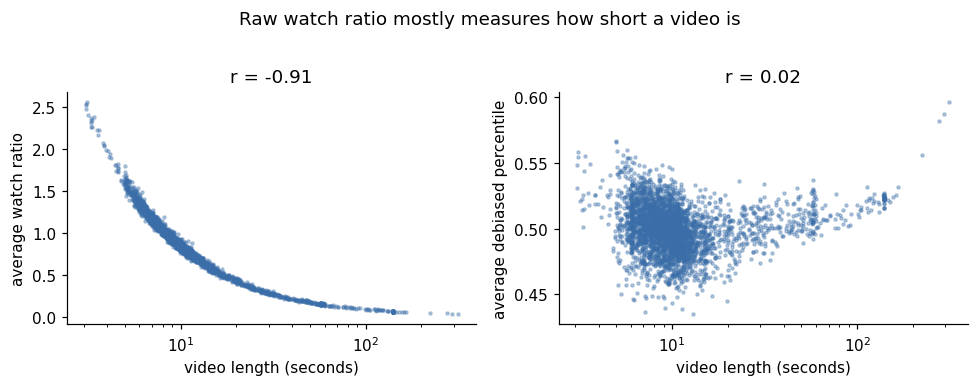

In [2]:
item_wr = np.nanmean(np.clip(truth, 0, 5), 0)
item_q = np.nanmean(truth_q, 0)
r_raw = np.corrcoef(item_wr, log_dur)[0, 1]
r_q = np.corrcoef(item_q, log_dur)[0, 1]

def var_share(R):
    m, im, um = np.nanmean(R), np.nanmean(R, 0), np.nanmean(R, 1)
    ok = ~np.isnan(R); tot = np.nanvar(R)
    item = np.var(np.broadcast_to(im, R.shape)[ok]); user = np.var(np.broadcast_to(um[:, None], R.shape)[ok])
    return item / tot, user / tot, np.nanvar(R - im - um[:, None] + m) / tot

vs = pd.DataFrame([var_share(np.clip(truth, 0, 5)), var_share(truth_q)],
                  index=["raw watch ratio", "debiased percentile"], columns=["video", "user", "user x video"])
print(f"Correlation of a video's average with its log length: raw {r_raw:.2f}, debiased {r_q:.2f}")
print("\nShare of variance explained by")
print(vs.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
for ax, y, lab, r in [(axes[0], item_wr, "average watch ratio", r_raw), (axes[1], item_q, "average debiased percentile", r_q)]:
    ax.scatter(np.expm1(log_dur) / 1000, y, s=4, alpha=.35, color=BLUE)
    ax.set_xscale("log"); ax.set(xlabel="video length (seconds)", ylabel=lab, title=f"r = {r:.2f}")
fig.suptitle("Raw watch ratio mostly measures how short a video is", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "03_duration_bias.png", bbox_inches="tight")

On raw watch ratio a video's length explains most of what a "good" video is. On the debiased percentile the video itself explains only a small share, and the user x video match carries most of the signal. That is the part a personalised recommender should capture.

## 2. How well do the models fit their own targets?

Trained on 1,084,277 label-period views, validated on 115,723 views from held-out users
raw       target: best iteration 85, validation RMSE 0.7110 vs 0.8050 for predicting the mean (11.7% lower)
debiased  target: best iteration 46, validation RMSE 0.2749 vs 0.2851 for predicting the mean (3.6% lower)


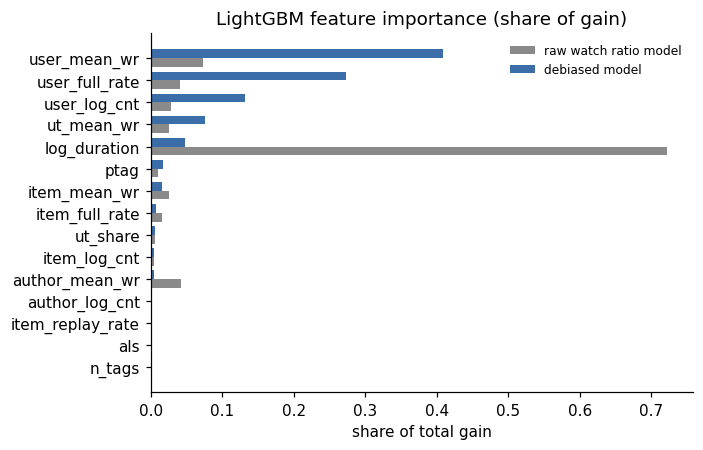

In [3]:
print((ART / "train_log.txt").read_text())
imps = {t: pd.read_csv(ART / f"lgbm_{t}_importance.csv", index_col=0).iloc[:, 0] for t in ["raw", "debiased"]}
imp = pd.DataFrame({t: v / v.sum() for t, v in imps.items()}).sort_values("debiased")
fig, ax = plt.subplots(figsize=(6.5, 4.2))
y = np.arange(len(imp))
ax.barh(y - .2, imp.raw, .4, color=GREY, label="raw watch ratio model")
ax.barh(y + .2, imp.debiased, .4, color=BLUE, label="debiased model")
ax.set_yticks(y, imp.index); ax.legend(frameon=False, fontsize=8)
ax.set(title="LightGBM feature importance (share of gain)", xlabel="share of total gain")
fig.tight_layout(); fig.savefig(FIG / "03_feature_importance.png")

The raw model leans almost entirely on video length. The debiased model spreads its weight across user, user x tag and author signals.

## 3. Baselines on the fully observed small matrix

Every policy turns a score matrix into a top 10 per user. Videos a user blocked are never recommended.

| Policy | What it does |
|---|---|
| Random | The floor |
| Most viewed | Most views in the big matrix. Same list for everyone |
| Best watched (raw) | Highest average raw watch ratio. Same list for everyone |
| Best watched (debiased) | Highest average debiased percentile. Same list for everyone |
| ALS | Collaborative filtering only |
| LightGBM raw | The naive model, trained on raw watch ratio |
| **LightGBM debiased** | **The baseline for Phase 4** |
| Oracle | Sorts by the true debiased percentile. Nothing can beat it |

In [4]:
rng = np.random.default_rng(0)
scores = {
    "Random": rng.random((U, I), dtype=np.float32),
    "Most viewed": z["pop"],
    "Best watched (raw)": z["qual_raw"],
    "Best watched (debiased)": z["qual_debiased"],
    "ALS": z["als"],
    "LightGBM raw": z["lgbm_raw"],
    "LightGBM debiased": z["lgbm_debiased"],
    "Oracle": np.nan_to_num(truth_q, nan=-1),
}
tiers = author_tiers(item_views, author)
tops, per_user, rows = {}, {}, {}
for name, s in scores.items():
    tops[name] = topk_from_scores(s, truth, K)
    per_user[name], rows[name] = evaluate(tops[name], truth_q, truth, ptag, author, item_views, tiers, secs)
res = pd.DataFrame(rows).T
res["video_secs"] = {n: secs[t].mean() for n, t in tops.items()}
cols = ["ndcg", "rel", "top20_rate", "watch_secs", "video_secs", "mean_wr", "full_rate", "distinct_tags", "ild",
        "creator_gini", "tail_share", "catalog_coverage"]
res[cols].round(3)

,ndcg,rel,top20_rate,watch_secs,video_secs,mean_wr,full_rate,distinct_tags,ild,creator_gini,tail_share,catalog_coverage
Random,0.507,0.501,0.198,8.373,14.597000,0.876,0.323,7.173,0.916,0.425,0.542,0.986
Most viewed,0.518,0.513,0.162,8.779,22.542000,0.612,0.174,5.077,0.805,0.996,0.000,0.004
Best watched (raw),0.547,0.539,0.334,7.798,3.232000,2.417,0.911,4.965,0.841,0.995,0.900,0.004
Best watched (debiased),0.543,0.539,0.182,8.990,93.577003,0.898,0.390,6.002,0.889,0.995,0.800,0.003
ALS,0.508,0.503,0.222,8.368,9.432000,1.020,0.437,6.234,0.855,0.805,0.619,0.448
LightGBM raw,0.540,0.532,0.321,7.760,3.290000,2.362,0.908,4.515,0.740,0.995,0.926,0.005
LightGBM debiased,0.571,0.561,0.249,8.513,58.023998,1.338,0.602,3.870,0.625,0.970,0.819,0.080
Oracle,1.000,0.988,0.996,39.896,10.258000,4.113,0.995,6.694,0.882,0.555,0.496,0.939


How to read the columns
- `ndcg`, `rel`, `top20_rate`. Relevance on the debiased percentile. `rel` is the average percentile of the 10 recommended videos (0.5 is what random gets). `top20_rate` is the share of recommended videos the user watched better than 80% of plays, after adjusting for length.
- `watch_secs`. Expected seconds actually watched per recommended video (watch ratio x length). This is closest to what a platform is paid for. `video_secs` is the average length of what gets recommended.
- `mean_wr`, `full_rate`. Raw watch ratio, for reference. These reward short videos.
- `distinct_tags`, `ild`. Diversity inside each list.
- `creator_gini`, `tail_share`. How concentrated exposure is across authors, and how much of it goes to the bottom 80% of authors by views.
- `catalog_coverage`. Share of the 3,327 videos that appear in anyone's top 10.

In [5]:
base = "LightGBM debiased"
comp = []
for name in ["Best watched (debiased)", "ALS", "LightGBM raw"]:
    for m in ["ndcg", "rel"]:
        d, lo, hi = paired_bootstrap(per_user[name][m], per_user[base][m])
        comp.append({"baseline minus": name, "metric": m, "diff": d, "lo": lo, "hi": hi})
print("Paired bootstrap over 1,411 users, 95% intervals")
pd.DataFrame(comp).round(4)

Paired bootstrap over 1,411 users, 95% intervals


,baseline minus,metric,diff,lo,hi
0,Best watched (debiased),ndcg,0.0274,0.0205,0.0346
1,Best watched (debiased),rel,0.0217,0.0158,0.0280
2,ALS,ndcg,0.0626,0.0547,0.0706
3,ALS,rel,0.0580,0.0508,0.0652
4,LightGBM raw,ndcg,0.0303,0.0228,0.0383
5,LightGBM raw,rel,0.0287,0.0220,0.0361


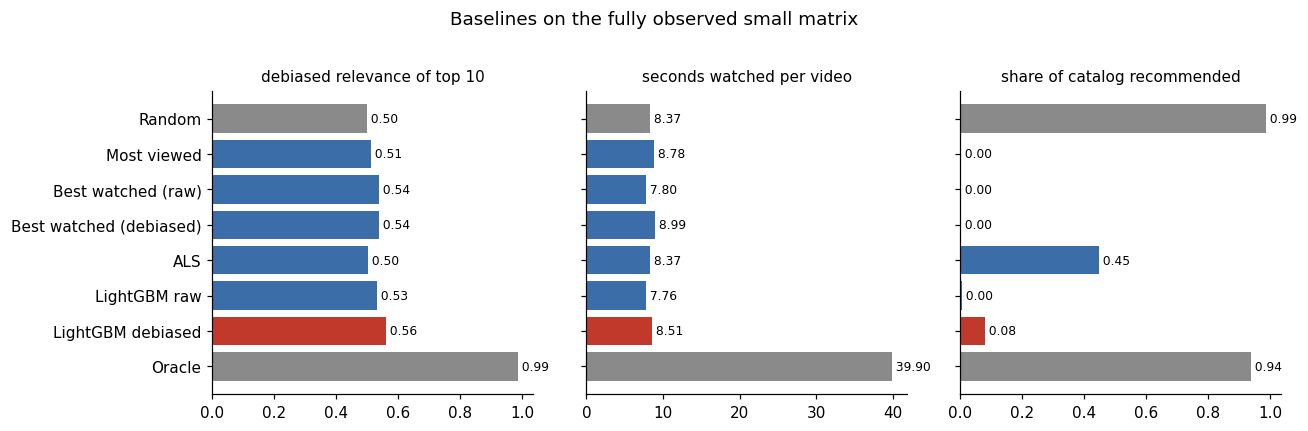

In [6]:
show = ["Random", "Most viewed", "Best watched (raw)", "Best watched (debiased)", "ALS",
        "LightGBM raw", "LightGBM debiased", "Oracle"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (m, lab) in zip(axes, [("rel", "debiased relevance of top 10"), ("watch_secs", "seconds watched per video"),
                               ("catalog_coverage", "share of catalog recommended")]):
    vals = res.loc[show, m]
    colors = [GREY if n in ("Random", "Oracle") else (RED if n == base else BLUE) for n in show]
    ax.barh(range(len(show)), vals, color=colors)
    ax.set_yticks(range(len(show)), show if ax is axes[0] else [""] * len(show))
    ax.invert_yaxis(); ax.set_title(lab, fontsize=10)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
fig.suptitle("Baselines on the fully observed small matrix", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "03_baselines.png", bbox_inches="tight")

## 4. What the baseline's lists look like

Tags reached by LightGBM debiased: 22 of 30
Videos that appear in anyone's top 10: 267 of 3,327
Top 3 tags take 48% of all recommendation slots (vs 26% of the catalog)


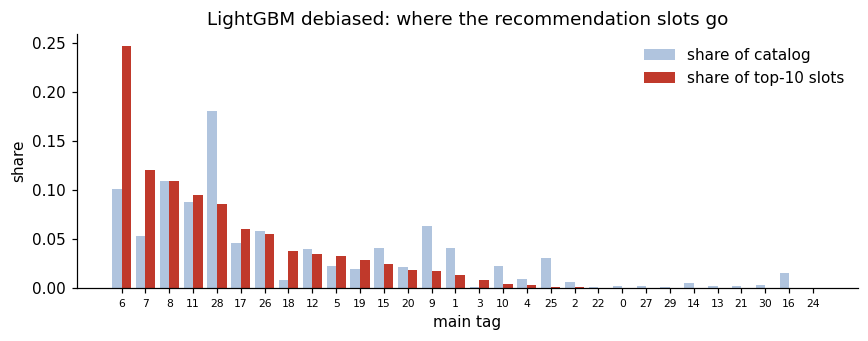

In [7]:
top = tops[base]
tag_share_rec = pd.Series(ptag[top.ravel()]).value_counts(normalize=True)
tag_share_cat = pd.Series(ptag).value_counts(normalize=True)
t = pd.concat([tag_share_cat.rename("catalog"), tag_share_rec.rename("recommended")], axis=1).fillna(0)
t = t.sort_values("recommended", ascending=False)
print(f"Tags reached by {base}: {rows[base]['tags_reached']} of {len(tag_share_cat)}")
print(f"Videos that appear in anyone's top 10: {len(np.unique(top)):,} of {I:,}")
print(f"Top 3 tags take {t.recommended.head(3).sum():.0%} of all recommendation slots "
      f"(vs {t.catalog.head(3).sum():.0%} of the catalog)")

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(t))
ax.bar(x - .2, t.catalog, .4, color="#b0c4de", label="share of catalog")
ax.bar(x + .2, t.recommended, .4, color=RED, label="share of top-10 slots")
ax.set_xticks(x, t.index.astype(str), fontsize=7)
ax.set(title=f"{base}: where the recommendation slots go", xlabel="main tag", ylabel="share")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "03_baseline_tag_concentration.png")

In [8]:
tier_rows = {n: {"head": rows[n]["head_share"], "mid": rows[n]["mid_share"], "tail": rows[n]["tail_share"]}
             for n in ["Random", "Most viewed", "ALS", "LightGBM raw", base]}
tt = pd.DataFrame(tier_rows).T
tt.loc["Catalog (videos)"] = pd.Series(author).map(tiers).value_counts(normalize=True).reindex(["head", "mid", "tail"]).values
print("Share of recommendation slots by author tier (head = top 1% of authors by views, mid = next 19%)")
tt.round(3)

Share of recommendation slots by author tier (head = top 1% of authors by views, mid = next 19%)


,head,mid,tail
Random,0.086,0.373,0.542
Most viewed,0.399,0.601,0.000
ALS,0.050,0.331,0.619
LightGBM raw,0.000,0.074,0.926
LightGBM debiased,0.027,0.154,0.819
Catalog (videos),0.087,0.378,0.535


## 5. Save the baseline for Phase 4

In [9]:
out = {n: {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v))
           for k, v in rows[n].items()} for n in rows}
(ROOT / "reports" / "phase3_baselines.json").write_text(json.dumps(out, indent=2))
r, o, g = res.loc[base], res.loc["Oracle"], res.loc["Best watched (debiased)"]
print(f"{base}: rel {r.rel:.3f} (global list {g.rel:.3f}, oracle {o.rel:.3f}, random 0.500)")
print(f"  share of the gap from random to oracle closed: {(r.rel - .5) / (o.rel - .5):.0%}")
print(f"  distinct tags {r.distinct_tags:.2f}, catalog coverage {r.catalog_coverage:.1%}, creator Gini {r.creator_gini:.3f}")

LightGBM debiased: rel 0.561 (global list 0.539, oracle 0.988, random 0.500)
  share of the gap from random to oracle closed: 12%
  distinct tags 3.87, catalog coverage 8.0%, creator Gini 0.970


## Takeaways

1. **Choosing the target was the biggest modelling decision.** Optimising raw watch ratio gives a feed of the shortest clips, the same for everyone, because watch ratio mostly measures length. Those 3-second clips earn *fewer* seconds of actual viewing than random picks. The debiased model earns about 10% more watch time than the raw model (8.5 vs 7.8 seconds per video). The best global debiased list earns a little more watch time by showing everyone the same few long videos, but the personalised model wins on relevance. Debiasing for duration is what makes personalisation pay off.
2. **The debiased LightGBM is the baseline.** It beats the best global list and ALS on relevance, with paired bootstrap intervals above. Personalisation buys real but modest headroom here. Most of the gap to the oracle is noise that no model could predict.
3. **It is still very concentrated.** A few tags and a small slice of the catalog take most of the slots. That is the before picture for Phase 4, and what the injection policy is meant to fix without giving back the relevance gain.

**Caveats.** The small matrix was collected by showing users a large share of the catalog, so it has some popularity bias. Every policy is scored on the same data, though, so comparisons between them are fair. The oracle is scored on the same noisy outcomes it sorts by, so it overstates what any model could reach.